# Example 22: Truncated wedge versus the apex solution

Gazetas and Dakoulas (1992) idealize a dam as a shear wedge whose width goes to zero at the crest: the crest is the apex. A real dam has a crest of finite width $b$, and the section that carries the shear is the wedge *truncated* at a distance $r_0 = b / (2 s)$ from the apex, where $s$ is the horizontal run of each slope per unit height. The truncated wedge has a free surface at the crest, and a wave there is reflected rather than focused into a point.

`pystrata.dam` solves both. A `Dam` without a slope is the apex wedge of the paper; a `Dam` with `slope` and `crest_width` is the truncated wedge. This example shows how much the crest width matters, by

1. the closed-form natural frequencies,
2. the transfer function of a homogeneous dam on rock, with the closed forms of both wedges and the numerical solution, and
3. an inhomogeneous dam ($G \propto z^{2/3}$), for which there is no closed form for the truncated wedge.

The apex solution is evaluated for the same height $H$ and average shear-wave velocity as the truncated one, which is what is done when the crest is ignored.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pystrata import dam, site
from pystrata.dam import analytical

%matplotlib inline

## Dams

A 50 m homogeneous rockfill dam ($V_s$ = 300 m/s, 5% damping) with 2.5H:1V slopes on rock at 1500 m/s, and crest widths of 10, 25 and 50 m. The rock is the half space; the input is its outcrop. The apex dam is the same height and velocity with no slope.

In [2]:
HEIGHT = 50.0  # m
VEL = 300.0  # m/s
DAMPING = 0.05
SLOPE = 2.5
CREST_WIDTHS = [10.0, 25.0, 50.0]

fill = site.SoilType("rockfill", 21.0, None, DAMPING)
rock = site.SoilType("rock", 25.0, None, 0.0)
foundation = site.Profile([site.Layer(rock, 1.0, 1500.0)])
imped_ratio = fill.unit_wt * VEL / (rock.unit_wt * 1500.0)


def make_dam(crest_width=None, m=0.0, shear_vel_avg=VEL, n_layers=20):
    """Apex dam if `crest_width` is None, otherwise the truncated dam."""
    kwds = {} if crest_width is None else dict(slope=SLOPE, crest_width=crest_width)
    return dam.Dam.from_inhomogeneity(
        fill, HEIGHT, shear_vel_avg, m=m, n_layers=n_layers, **kwds
    )


truncated = {b: make_dam(b) for b in CREST_WIDTHS}
for b, d in truncated.items():
    print(
        f"b = {b:4.0f} m: crest offset r0 = {d.crest_offset:5.1f} m, r0 / H = {d.crest_offset / HEIGHT:.2f}"
    )

b =   10 m: crest offset r0 =   2.0 m, r0 / H = 0.04
b =   25 m: crest offset r0 =   5.0 m, r0 / H = 0.10
b =   50 m: crest offset r0 =  10.0 m, r0 / H = 0.20


## Natural frequencies

The natural frequencies of the dam on a rigid base are the roots of $J_0(kR)$ for the apex wedge and of $J_0(kR)\,Y_1(k r_0) - Y_0(kR)\,J_1(k r_0)$ for the truncated wedge, with $R = r_0 + H$. Truncating the apex adds the length $r_0$ to the beam that carries the shear, so every frequency drops, and the higher modes drop relatively less.

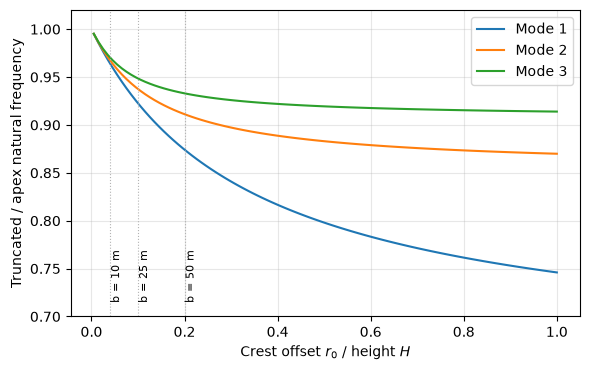

In [3]:
ratios = np.linspace(0.005, 1.0, 100)  # r0 / H
f_apex = analytical.wedge_natural_freqs(HEIGHT, VEL, n=3)
f_trunc = np.array(
    [
        analytical.wedge_truncated_natural_freqs(HEIGHT, VEL, r * HEIGHT, n=3)
        for r in ratios
    ]
)

fig, ax = plt.subplots(figsize=(6, 3.8))
for mode in range(3):
    ax.plot(ratios, f_trunc[:, mode] / f_apex[mode], label=f"Mode {mode + 1}")
for b, d in truncated.items():
    ax.axvline(d.crest_offset / HEIGHT, color="0.7", lw=0.8, ls=":")
    ax.text(
        d.crest_offset / HEIGHT,
        0.71,
        f" b = {b:.0f} m",
        rotation=90,
        va="bottom",
        fontsize=8,
    )
ax.set(
    xlabel="Crest offset $r_0$ / height $H$",
    ylabel="Truncated / apex natural frequency",
    ylim=(0.7, 1.02),
)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

## Homogeneous dam: closed forms and numerical solution

The crest-to-outcrop transfer function for the apex wedge is $1 / (J_0(a_0) + i \alpha J_1(a_0))$ (Table 2 of the paper). `dam.analytical` has the equivalent for the truncated wedge. The numerical solution of `pystrata.dam` with 20 layers is compared to both, to confirm the implementation and to show the effect of the crest.

In [4]:
freqs = np.geomspace(0.2, 40, 800)


def numerical_tf(d):
    return dam.DamProfile(d, foundation).transfer_function(freqs)


apex_exact = analytical.wedge_elastic_base_tf(freqs, HEIGHT, VEL, DAMPING, imped_ratio)
apex_num = numerical_tf(make_dam())

trunc_exact, trunc_num = {}, {}
for b, d in truncated.items():
    trunc_exact[b] = analytical.wedge_truncated_elastic_base_tf(
        freqs, HEIGHT, VEL, DAMPING, imped_ratio, d.crest_offset
    )
    trunc_num[b] = numerical_tf(d)

print(
    "max |numerical - closed form|: apex",
    f"{np.abs(apex_num - apex_exact).max():.3f},",
    "truncated",
    ", ".join(
        f"{np.abs(trunc_num[b] - trunc_exact[b]).max():.3f}" for b in CREST_WIDTHS
    ),
)

max |numerical - closed form|: apex 0.000, truncated 0.000, 0.000, 0.000


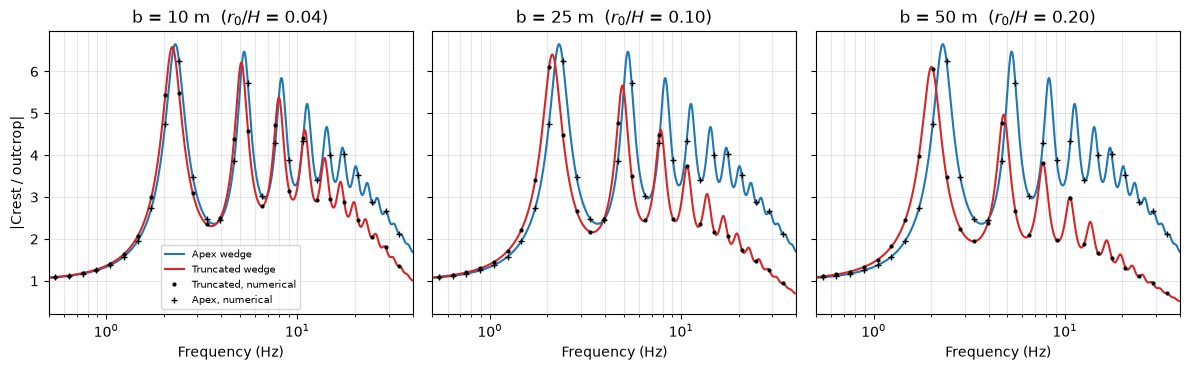

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, b in zip(axes, CREST_WIDTHS):
    ax.plot(freqs, np.abs(apex_exact), "C0-", label="Apex wedge")
    ax.plot(freqs, np.abs(trunc_exact[b]), "C3-", label="Truncated wedge")
    ax.plot(
        freqs[::25],
        np.abs(trunc_num[b])[::25],
        "k.",
        ms=4,
        label="Truncated, numerical",
    )
    ax.plot(freqs[::25], np.abs(apex_num)[::25], "k+", ms=4, label="Apex, numerical")
    ax.set(
        xscale="log",
        xlim=(0.5, 40),
        xlabel="Frequency (Hz)",
        title=f"b = {b:.0f} m  ($r_0 / H$ = {truncated[b].crest_offset / HEIGHT:.2f})",
    )
    ax.grid(True, which="both", alpha=0.3)
axes[0].set_ylabel("|Crest / outcrop|")
axes[0].legend(fontsize=7)
fig.tight_layout()

In [6]:
import pandas as pd


def first_peak(amp):
    i = np.nonzero((amp[1:-1] > amp[:-2]) & (amp[1:-1] >= amp[2:]))[0][0] + 1
    return freqs[i], amp[i]


f0, a0 = first_peak(np.abs(apex_exact))
rows = [
    {
        "b (m)": 0.0,
        "r0 / H": 0.0,
        "f1 (Hz)": f0,
        "peak": a0,
        "f1 shift": 0.0,
        "peak change": 0.0,
    }
]
for b in CREST_WIDTHS:
    f1, a1 = first_peak(np.abs(trunc_exact[b]))
    rows.append(
        {
            "b (m)": b,
            "r0 / H": truncated[b].crest_offset / HEIGHT,
            "f1 (Hz)": f1,
            "peak": a1,
            "f1 shift": f1 / f0 - 1,
            "peak change": a1 / a0 - 1,
        }
    )
pd.DataFrame(rows).round(3).set_index("b (m)")

,r0 / H,f1 (Hz),peak,f1 shift,peak change
b (m),,,,,
0.0,0.00,2.295,6.651,0.000,0.000
10.0,0.04,2.220,6.583,-0.033,-0.010
25.0,0.10,2.120,6.406,-0.076,-0.037
50.0,0.20,2.010,6.109,-0.124,-0.081


## Inhomogeneous dam

For a dam with $G \propto z^{2/3}$, the case of Example 20, only the apex wedge has a closed form. The truncated one is solved numerically. Both have the same height and area-weighted average velocity of 300 m/s, so the difference is the crest.

,f1 (Hz),peak,f1 shift,peak change
b (m),,,,
0.0,2.357,8.866,0.000,0.000
10.0,2.265,8.410,-0.039,-0.052
25.0,2.177,7.747,-0.076,-0.126
50.0,2.064,6.983,-0.124,-0.212


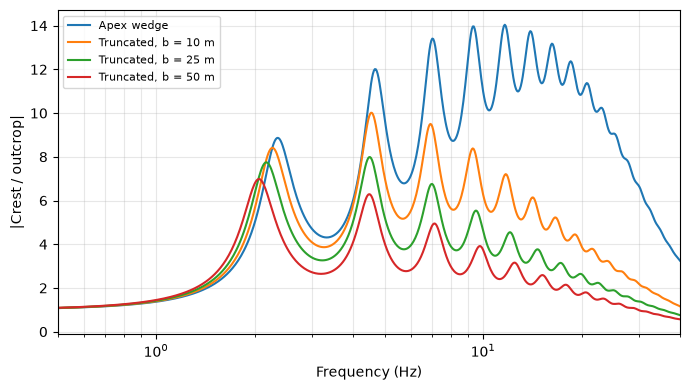

In [7]:
M = 2 / 3
apex_m = numerical_tf(make_dam(m=M, n_layers=40))
trunc_m = {b: numerical_tf(make_dam(b, m=M, n_layers=40)) for b in CREST_WIDTHS}

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(freqs, np.abs(apex_m), "C0-", label="Apex wedge")
for k, b in enumerate(CREST_WIDTHS):
    ax.plot(
        freqs, np.abs(trunc_m[b]), color=f"C{k + 1}", label=f"Truncated, b = {b:.0f} m"
    )
ax.set(
    xscale="log", xlim=(0.5, 40), xlabel="Frequency (Hz)", ylabel="|Crest / outcrop|"
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

rows = []
f0, a0 = first_peak(np.abs(apex_m))
rows.append(
    {"b (m)": 0.0, "f1 (Hz)": f0, "peak": a0, "f1 shift": 0.0, "peak change": 0.0}
)
for b in CREST_WIDTHS:
    f1, a1 = first_peak(np.abs(trunc_m[b]))
    rows.append(
        {
            "b (m)": b,
            "f1 (Hz)": f1,
            "peak": a1,
            "f1 shift": f1 / f0 - 1,
            "peak change": a1 / a0 - 1,
        }
    )
pd.DataFrame(rows).round(3).set_index("b (m)")

### Observations

- **The crest lowers the natural frequencies, mostly the first.** For $r_0 / H$ of 0.04, 0.10 and 0.20 (crests of 10, 25 and 50 m on the 50 m dam) the first frequency of the homogeneous dam drops 3%, 8% and 12% (table above), the second 3%, 6% and 9%, and the third 3%, 5% and 7%.
- **The first peak is nearly unchanged, the higher modes are not.** The amplitude of the first peak changes by 1%, 4% and 8% for the homogeneous dam, but the response above it falls steadily with the crest width: at 10 Hz the crest of the truncated dam amplifies 96%, 85% and 72% of the apex wedge. The apex is a point, so ignoring the crest overstates the high-frequency amplification.
- **The inhomogeneous dam is more sensitive**: its first frequency drops by 4%, 8% and 12%, but its first peak is 5%, 13% and 21% lower.
- **The numerical solution agrees with the closed forms** of both wedges for the homogeneous dam (to the precision printed), which checks the free surface at the crest in the layered implementation. The inhomogeneous truncated wedge has no closed form and relies on that check.
- **When to include the crest.** For $r_0 / H$ below about 0.05 the apex solution is within a few percent in frequency and in the first peak. A broader crest, or an interest in the response at high frequencies, calls for the truncated wedge: give `Dam` a `slope` and `crest_width`.